# Fintual: Fincard
Integrantes: Iair Chistik, Francisco Cisternas y Agustin rosales

In [31]:
# Librerias 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuraciones de visualización
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

In [2]:
# Carga de los datos inicales
diccionario = pd.read_csv("diccionario_datos_2026.csv")
fintual_percepcion = pd.read_csv("fintual_perception_dataset_2026.csv")
usuarios = pd.read_csv("fintual_users_dataset_2026.csv")
caracteristicas = pd.read_csv("user_demographics_2026.csv")

### EDA DE DIAGNOSTICO
El objetivo de realizar un EDA en esta fase es diagnosticar el estado en el que se encuentran las bases de datos para encontrar anomalias como datos fuera de rango, valores nulos, duplicados, errores de digitacio, etc. Los objetivos son:
- Dimensiones
- Valores duplicados
- Valores nulos 
- Anomalias de digitación 
- Valores fuera de rango 
- Valores atipicos

In [3]:
# Inspección de los tablas (Dimensiones)
base_datos = {
    "usuarios": usuarios,
    "caracteristicas": caracteristicas,
    "fintual_percepcion": fintual_percepcion
}
for nombre, tablas in base_datos.items():
    filas, columnas = tablas.shape
    print(f"El dataset '{nombre}' tiene {filas} filas y {columnas} columnas.")

El dataset 'usuarios' tiene 12025 filas y 6 columnas.
El dataset 'caracteristicas' tiene 12000 filas y 11 columnas.
El dataset 'fintual_percepcion' tiene 21000 filas y 12 columnas.


In [4]:
# Usuarios unicos 
usuarios_unicos = usuarios['user_id'].nunique()
print(f"Usuarios unicos: {usuarios_unicos}")
usuarios_unicos_caracteristicas = caracteristicas['user_id'].nunique()
print(f"Usuarios unicos en caracteristicas: {usuarios_unicos_caracteristicas}")
usuarios_unicos_percepcion = fintual_percepcion['user_id'].nunique()
print(f"Usuarios unicos en percepcion: {usuarios_unicos_percepcion}")

Usuarios unicos: 12000
Usuarios unicos en caracteristicas: 12000
Usuarios unicos en percepcion: 3000


In [5]:
# Estadisticos usuarios
usuarios.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"11,840.00",33.61,10.17,0.00,25.00,33.00,40.00,150.00
total_invested,"12,025.00","8,106,127.96","13,929,064.99","15,500.00","302,300.00","2,824,300.00","9,637,000.00","239,386,000.00"
risk_tolerance,"11,647.00",3.22,1.21,0.00,2.00,3.00,4.00,5.00
months_active,"12,025.00",32.54,22.28,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"11,581.00",20.97,10.01,1.00,13.00,21.00,29.00,47.00


In [6]:
# Estadisticos caracteristicas
caracteristicas.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,12000,12000,FTL_00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,11881,16,Metropolitana de Santiago,6830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,11772,3,Masculino,6204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tramo_ingreso,11009,5,$1.200.001 - $2.500.000,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ocupacion,12000,5,Dependiente,7707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
banco_principal,12000,12,Banco de Chile,2340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tiene_tarjeta_credito,12000,2,Sí,7989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_tarjetas_credito,"12,000.00",NaN,NaN,NaN,1.20,1.07,0.00,0.00,1.00,2.00,4.00
billetera_digital_principal,12000,5,Ninguna,4444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gasto_mensual_tarjetas_clp,"12,000.00",NaN,NaN,NaN,"1,155,643.58","1,046,950.30","48,000.00","440,000.00","848,000.00","1,519,000.00","14,602,000.00"


In [7]:
# Estadisticos percepcion
fintual_percepcion.describe().T

,count,mean,std,min,25%,50%,75%,max
ease_of_use,"20,202.00",5.57,1.17,1.00,5.00,6.00,7.00,7.00
fees_transparency,"20,016.00",4.75,1.39,1.00,4.00,5.00,6.00,7.00
investment_options,"19,882.00",4.54,1.44,1.00,4.00,5.00,6.00,7.00
customer_support,"19,779.00",4.68,1.18,1.00,4.00,5.00,5.00,7.00
mobile_experience,"20,168.00",5.63,1.15,1.00,5.00,6.00,7.00,7.00
educational_content,"20,029.00",4.26,1.40,1.00,3.00,4.00,5.00,7.00
trust_security,"20,228.00",5.27,1.13,1.00,5.00,5.00,6.00,7.00
returns_performance,"19,521.00",4.67,1.23,1.00,4.00,5.00,6.00,7.00
social_impact,"19,360.00",4.28,1.21,1.00,3.00,4.00,5.00,7.00
innovation,"20,020.00",5.20,1.35,1.00,4.00,5.00,6.00,7.00


In [8]:
# Detalle especifico de los nulos por base y columna
def resumen_nulos(diccionario_dfs):
    for nombre, df in diccionario_dfs.items():
        conteo_nulos = df.isnull().sum()
        porcentaje_nulos = (df.isnull().mean() * 100).round(2)
        
        # Armamos el DataFrame resumen
        resumen = pd.DataFrame({
            "Nulos": conteo_nulos,
            "% Nulos": porcentaje_nulos
        })
        
        print(f"-------- Nulos en '{nombre}' (Total filas: {len(df)}) --------")
        display(resumen)

resumen_nulos(base_datos)


-------- Nulos en 'usuarios' (Total filas: 12025) --------


,Nulos,% Nulos
user_id,0,0.00
age,185,1.54
total_invested,0,0.00
risk_tolerance,378,3.14
months_active,0,0.00
app_sessions_month,444,3.69


-------- Nulos en 'caracteristicas' (Total filas: 12000) --------


,Nulos,% Nulos
user_id,0,0.00
region,119,0.99
genero,228,1.90
tramo_ingreso,991,8.26
ocupacion,0,0.00
banco_principal,0,0.00
tiene_tarjeta_credito,0,0.00
n_tarjetas_credito,0,0.00
billetera_digital_principal,0,0.00
gasto_mensual_tarjetas_clp,0,0.00


-------- Nulos en 'fintual_percepcion' (Total filas: 21000) --------


,Nulos,% Nulos
user_id,0,0.00
brand,0,0.00
ease_of_use,798,3.80
fees_transparency,984,4.69
investment_options,1118,5.32
customer_support,1221,5.81
mobile_experience,832,3.96
educational_content,971,4.62
trust_security,772,3.68
returns_performance,1479,7.04


In [9]:
# Edades registradas que están fuera de 18 a 110
edades_invalidas = usuarios[usuarios['age'].notnull() & ~usuarios['age'].between(18, 110)]
print(f"Registros con edad inválida/imposible: {len(edades_invalidas)}")
display(edades_invalidas[['user_id', 'age']])
# Tolerancia de riesgo fuera de 1 a 5
tolerancia_invalidas = usuarios[usuarios['risk_tolerance'].notnull() & ~usuarios['risk_tolerance'].between(1, 5)]
print(f"Registros con tolerancia de riesgo inválida: {len(tolerancia_invalidas)}")
display(tolerancia_invalidas[['user_id', 'risk_tolerance']])

Registros con edad inválida/imposible: 15


,user_id,age
931,FTL_00930,17.00
1383,FTL_01382,150.00
1578,FTL_01576,0.00
2206,FTL_02203,17.00
2545,FTL_02540,17.00
3519,FTL_03510,17.00
4190,FTL_04179,17.00
4197,FTL_04186,7.00
5316,FTL_05303,3.00
5457,FTL_05443,17.00


Registros con tolerancia de riesgo inválida: 70


,user_id,risk_tolerance
240,FTL_00241,0.00
388,FTL_00389,0.00
987,FTL_00986,0.00
998,FTL_00997,0.00
1154,FTL_01153,0.00
...,...,...
10853,FTL_10831,0.00
10874,FTL_10852,0.00
11057,FTL_11035,0.00
11170,FTL_11148,0.00


### Limpieza de las bases de datos
Habiendo diagnosticado los registros duplicados, valores faltantes y datos fuera de rango, se procederá a:
1. **Eliminar registros duplicados** para asegurar unicidad por cliente (user_id).
2. **Analizar el patrón de los valores nulos** (MAR/MCAR) para aplicar una estrategia de imputación fundamentada por comportamiento y antigüedad.
3. **Tratar los datos fuera de rango** (edades imposibles y riesgo en 0) imputándolos bajo la misma lógica MAR para preservar los activos reales administrados y mantener la integridad referencial con la base demográfica.


In [10]:
# Eliminacion de datos duplicados en las bases de datos
usuarios_copia = usuarios.copy()
usuarios_copia = usuarios_copia.drop_duplicates(subset='user_id').reset_index(drop=True)

print(f"Filas totales en usuarios : {len(usuarios_copia)} y Filas totales en usuarios: {len(usuarios)}")
print(f"IDs unicos en usuarios_copia: {usuarios_copia['user_id'].nunique()}")

Filas totales en usuarios : 12000 y Filas totales en usuarios: 12025
IDs unicos en usuarios_copia: 12000


In [11]:
# Analisar los valores nulos en la columna edad
analisis_completo = usuarios_copia.merge(caracteristicas, on='user_id', how='left')

tabla_nulos_edad = (
    analisis_completo
    .assign(falta_edad=analisis_completo['age'].isnull())
    .groupby('falta_edad')
    .agg(
        total_usuarios=('user_id', 'count'),
        inversion_promedio=('total_invested', 'mean'), 
        meses_promedio=('months_active', 'mean'),
        gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean'),
        maximo_meses=('months_active', 'max') 
    )
    .assign(porcentaje=lambda x: (x['total_usuarios'] / x['total_usuarios'].sum() * 100).round(2))
)

print("----- Análisis de Nulos en EDAD -----")
display(tabla_nulos_edad.round(2))

----- Análisis de Nulos en EDAD -----


,total_usuarios,inversion_promedio,meses_promedio,gasto_tarjetas_prom,maximo_meses,porcentaje
falta_edad,,,,,,
False,11816,"7,964,324.39",32.27,"1,146,821.68",96,98.47
True,184,"17,586,988.04",51.15,"1,722,163.04",96,1.53


Al analizar los 184 valores faltantes en edad, podemos concluir que no son datos aleatorios. Corresponder a clientes con un antigüedad promedio de 51 meses y una inversion promedio de 17,58 millones de pesos. Por lo que podemos concluir que al inicio de fintual el formulario de registro era diferente a lo que es actulamente, capaz la edad no estaba calculada con la fecha de nacimiento y el usuario podria directamente no ingresar el dato pensado que asi funcionaba. Por lo tanto eliminar estos registros no es lo más adecuado. Esto corresponderia datos faltante por MAR. Como esto solo representa al 1,53% de los usuarios, lo mejor seria imputar con la mediana de los usuarios según la antiguedad similar entre ellos. lo mayores a 50 meses se les asigna con la media de sus pares y a los menores se les asignara la mediana general de los usuarios

In [12]:
# Calcular medianas
mediana_general = usuarios_copia['age'].median()
mediana_50meses = usuarios_copia[usuarios_copia['months_active'] >= 50]['age'].median()
print(f"Mediana de edad general: {mediana_general}")
print(f"Mediana de edad para usuarios con 50 o más meses activos: {mediana_50meses}")

# Rellenar los valores nulos de edad con la mediana correspondiente
usuarios_copia['age'] = usuarios_copia['age'].fillna(
    usuarios_copia['months_active'].apply(lambda x: mediana_50meses if x >= 50 else mediana_general)
)

Mediana de edad general: 33.0
Mediana de edad para usuarios con 50 o más meses activos: 43.0


In [13]:
# Analisis valores nulos en la columna risk_tolerance
tabla_nulos_riesgo = (
    analisis_completo
    .assign(falta_riesgo=analisis_completo['risk_tolerance'].isnull())
    .groupby('falta_riesgo')
    .agg(
        total_usuarios=('user_id', 'count'),
        edad_promedio=('age', 'mean'),
        inversion_promedio=('total_invested', 'mean'),
        meses_promedio=('months_active', 'mean'),
        sesiones_app_prom=('app_sessions_month', 'mean'),
        gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean')
    )
    .assign(porcentaje=lambda x: (x['total_usuarios'] / x['total_usuarios'].sum() * 100).round(2))
)
print("----- Análisis de Nulos en TOLERANCIA AL RIESGO -----")
display(tabla_nulos_riesgo.round(2))

----- Análisis de Nulos en TOLERANCIA AL RIESGO -----


,total_usuarios,edad_promedio,inversion_promedio,meses_promedio,sesiones_app_prom,gasto_tarjetas_prom,porcentaje
falta_riesgo,,,,,,,
False,11623,33.77,"8,228,784.94",32.98,20.87,"1,167,259.57",96.86
True,377,28.60,"4,507,414.85",19.59,24.28,"797,519.89",3.14


Al analizar los 377 valores faltantes en la tolerancia al riesgo, podemos concluir que no son datos aleatorios. Comparandolos con los usarios que si presentan tolerancia al riesgo (1 a 5) podemos decir que son mas jovenes, invierten aproximadamente la mitad y tiene menos tiempo en el servicio. Por lo que se puede decir que son usuarios que aun estan explorando la app o la usan de una manera muy cautelosa por lo que no se les ha asignado un perfil de riesgo. Lo calificamos como datos MAR y se rellenara usando la mediana, ya que son jovenes y se le puede asignar un perfil neutral de riesgo.

In [14]:
# Calcular mediana
mediana_riesgo = usuarios_copia['risk_tolerance'].median()
print(f"Mediana de tolerancia al riesgo: {mediana_riesgo}")

# Rellenar los valores nulos de tolerancia al riesgo con la mediana correspondiente
usuarios_copia['risk_tolerance'] = usuarios_copia['risk_tolerance'].fillna(mediana_riesgo)

Mediana de tolerancia al riesgo: 3.0


In [15]:
# Analizar los valores nulos los inicios mensuales de sesión en la app
tabla_nulos_sesiones = (
    analisis_completo
    .assign(falta_sesiones=analisis_completo['app_sessions_month'].isnull())
    .groupby('falta_sesiones')
    .agg(
        total_usuarios=('user_id', 'count'),
        inversion_promedio=('total_invested', 'mean'),
        meses_promedio=('months_active', 'mean'),
        edad_promedio=('age', 'mean')
    ))
print("----- Análisis de Nulos en SESIONES APP -----")
display(tabla_nulos_sesiones.round(2))

----- Análisis de Nulos en SESIONES APP -----


,total_usuarios,inversion_promedio,meses_promedio,edad_promedio
falta_sesiones,,,,
False,11558,"8,129,083.30",32.60,33.64
True,442,"7,661,805.43",31.45,32.84


Observando los valores nulos de las sesiones en app. En un inicio pensabamos que podria haber una relacion entre la inversion promedio, meses promedio ya que pudieron haber sido usuarios que se crearon la cuenta pero por miedo nunca mas volvieron a ingresar, sin emabrgo, se muestra todo lo contrario tiene una inversion promedio cercana a los que si tiene registros de sesiones, tiene en promedio la misma antiguedad. Por lo que lo mejor es imputar con la mediana.

In [16]:
# calcular la mediana de sesiones mensuales en la app
mediana_sesiones = usuarios_copia['app_sessions_month'].median()
print(f"Mediana de sesiones mensuales en la app: {mediana_sesiones}")

# rellenar los valores nulos de sesiones mensuales en la app con la mediana correspondiente
usuarios_copia['app_sessions_month'] = usuarios_copia['app_sessions_month'].fillna(mediana_sesiones)

Mediana de sesiones mensuales en la app: 21.0


#### Tratamiento de los datos fuera de rango

En la fase de diagnóstico se identificaron dos tipos de anomalías de rango en la base de `usuarios`:
1. **Edad fuera de rango legal (18 a 110 años):** 15 registros (0,12% del total). Incluye errores de digitación evidentes (0, 3, 7, 112, 134 y 150 años) y 8 casos con 17 años (menores de edad, cuando el requisito legal y del diccionario es 18+).
2. **Tolerancia al riesgo fuera de escala (1 a 5):** 70 registros con valor `0.0` (0,58% del total). Dado que la escala va de 1 (muy conservador) a 5 (muy agresivo), el valor 0 corresponde a una codificación por defecto del sistema para cuentas no perfiladas o sin cuestionario completado.

**Criterio y justificación de tratamiento:**
* **¿Por qué no eliminar los registros?** Al examinar estos 85 clientes, se constata que corresponden a usuarios reales con actividad e inversiones significativas (por ejemplo, el usuario `FTL_05443` posee más de $74 millones invertidos y 67 meses de antigüedad). Eliminarlos sesgaría el volumen total de activos administrados y rompería la correspondencia 1 a 1 con la base demográfica (`user_demographics_2026.csv`), que contiene exactamente 12.000 clientes únicos.
* **Solución aplicada:** Se corrigen estos valores anómalos imputando según los mismos criterios fundamentados anteriormente para los datos MAR:
  - Para las **edades inválidas**, se asigna la mediana correspondiente según su grupo de antigüedad ($\ge 50$ meses recibe 43 años, $< 50$ meses recibe 33 años).
  - Para la **tolerancia al riesgo en 0**, se imputa con la mediana general (3.0), asignándoles un perfil neutral/moderado.


In [17]:
filtro_edad = usuarios_copia['user_id'].isin(edades_invalidas['user_id'])
filtro_riesgo = usuarios_copia['user_id'].isin(tolerancia_invalidas['user_id'])

print(f"Registros a corregir en edad (desde edades_invalidas): {filtro_edad.sum()}")
print(f"Registros a corregir en riesgo (desde tolerancia_invalidas): {filtro_riesgo.sum()}")

# 1. Tratamiento para edad: imputar según antigüedad (misma regla MAR justificada)
usuarios_copia.loc[filtro_edad, 'age'] = usuarios_copia.loc[filtro_edad, 'months_active'].apply(
    lambda x: mediana_50meses if x >= 50 else mediana_general
)

# 2. Tratamiento para tolerancia al riesgo: asignar mediana general (perfil moderado = 3.0)
usuarios_copia.loc[filtro_riesgo, 'risk_tolerance'] = mediana_riesgo

# Verificacion rapida
print("Nulos restantes:", usuarios_copia.isnull().sum().sum())
usuarios_copia.describe().T

Registros a corregir en edad (desde edades_invalidas): 15
Registros a corregir en riesgo (desde tolerancia_invalidas): 70
Nulos restantes: 0


,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00


In [18]:
# Tratamiento de los valores nulos en la tabla demográficos de los usuarios
caracteristicas_copia = caracteristicas.copy()

# Valores nulos en la columna 'gender' de la tabla de características
caracteristicas_copia['genero'] = caracteristicas_copia['genero'].fillna('Otro / Prefiere no decir')

# Valores nulos en region
moda_region = caracteristicas_copia['region'].mode()[0]
caracteristicas_copia['region'] = caracteristicas_copia['region'].fillna(moda_region)

# Valores nulos en tramo ingreso
caracteristicas_copia['tramo_ingreso'] = caracteristicas_copia['tramo_ingreso'].fillna("No declara")

# Comprobacion rapida
caracteristicas_copia.isna().sum()
 

user_id                           0
region                            0
genero                            0
tramo_ingreso                     0
ocupacion                         0
banco_principal                   0
tiene_tarjeta_credito             0
n_tarjetas_credito                0
billetera_digital_principal       0
gasto_mensual_tarjetas_clp        0
interes_fintual_card           3393
dtype: int64

In [ ]:
# Limpieza 

Los valores nulos de genero y region fueron considerados como MCAR. La gente se habra olvidado de rellenar esos datos. Para tramos ingresos consideramos esos datos faltantes como MNAR ya que en chile y en general esos datos son sensibles y la gente prefiere no comentarlos. Por ultimo decidimos dejar los valors nulos (NaN) del interes por la fintual card ya que en si es una respuesta, entrega informacion y es una variable para python numerica entonces no podemos imputarle texto u otro valor.

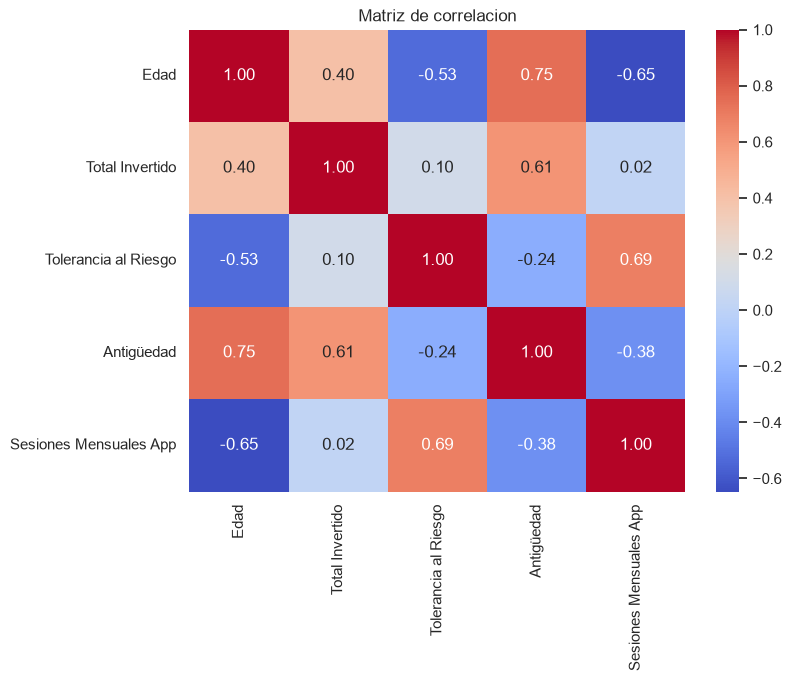

In [19]:
# Matriz de correlacion de los usuarios de fintual
variables = ['age','total_invested','risk_tolerance','months_active','app_sessions_month']

df_corr = usuarios_copia[variables].rename(columns={    'age': 'Edad',
    'total_invested': 'Total Invertido',
    'risk_tolerance': 'Tolerancia al Riesgo',
    'months_active': 'Antigüedad',
    'app_sessions_month': 'Sesiones Mensuales App'
})

matriz_corr = df_corr.corr()

# Graficar la matriz
plt.figure(figsize= (8,6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlacion")
plt.show()

#### Total invested, sesgo


C:\Users\20fac\AppData\Local\Temp\ipykernel_5512\2698476641.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


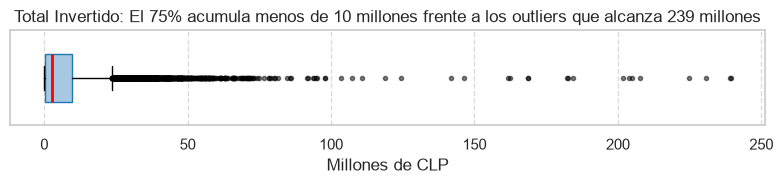

,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00


In [20]:
# Transformar los datos en millones de clp para ser legible
inversion_millones = usuarios_copia['total_invested'] / 1_000_000

# Boxplot de total_onvrsted para detectar outliers y distribucion
plt.figure(figsize=(8,2))
plt.boxplot(
    inversion_millones, 
    vert=False,
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor='#a6c8e0', color='#1f77b4'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5, markerfacecolor='black')
            )
plt.title("Total Invertido: El 75% acumula menos de 10 millones frente a los outliers que alcanza 239 millones")
plt.xlabel("Millones de CLP")
plt.yticks([])                     # Ocultamos la etiqueta del eje Y porque es una sola variable
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Estadisticos usuarios
estadistico_limpios = usuarios_copia.describe().T
display(estadistico_limpios)

Observando el boxplot podemos evidenciar la existencia de una fuerte asimetria en los datos. Los outlier aparecen a partir de los 23 millones alcanzado un maximo de 239 millones de pesos invertidos. Esto clientes representan una cantidad importante en los ingresos y los datos de fintual por lo que eliminar a los outlier no es recomendado, sin embargo, mantenerlos tal cual genera un problema a futuro a la hora de construir clusters o trabajar con modelos de machine learning. la accion recomendable es transformarlos con una escala logaritmica.

C:\Users\20fac\AppData\Local\Temp\ipykernel_5512\1723687104.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


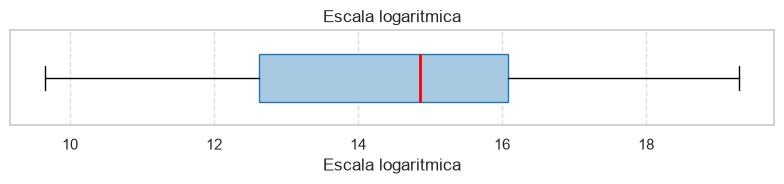

,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00
total_inv_log,"12,000.00",14.51,1.97,9.65,12.62,14.85,16.08,19.29


In [21]:
usuarios_copia['total_inv_log'] = np.log1p(usuarios_copia['total_invested'])
usuarios_copia.head()

# Boxplot de total_onvrsted para detectar outliers y distribucion
plt.figure(figsize=(8,2))
plt.boxplot(
    usuarios_copia['total_inv_log'], 
    vert=False,
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor='#a6c8e0', color='#1f77b4'),
    medianprops=dict(color='red', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5, markerfacecolor='black')
            )
plt.title("Escala logaritmica")
plt.xlabel("Escala logaritmica")
plt.yticks([])                     # Ocultamos la etiqueta del eje Y porque es una sola variable
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Estadisticos usuarios
estadistico_limpios = usuarios_copia.describe().T
display(estadistico_limpios)

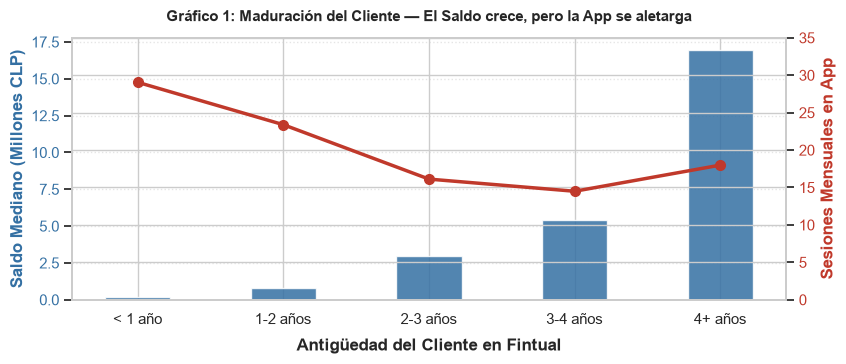

In [22]:
# GRAFICO 1: Matplotlib puro - Curva de maduracion del cliente
usuarios_copia['anios_activo'] = pd.cut(
    usuarios_copia['months_active'], 
    bins=[0, 12, 24, 36, 48, 100], 
    labels=['< 1 año', '1-2 años', '2-3 años', '3-4 años', '4+ años']
)

maduracion = usuarios_copia.groupby('anios_activo', observed=False).agg(
    saldo_mediano=('total_invested', lambda x: x.median() / 1_000_000),
    sesiones_prom=('app_sessions_month', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# 1. Barras: Saldo mediano acumulado
color_barras = '#3470a3'
ax1.bar(maduracion['anios_activo'], maduracion['saldo_mediano'], color=color_barras, width=0.45, alpha=0.85)
ax1.set_xlabel("Antigüedad del Cliente en Fintual", fontweight='bold', labelpad=8)
ax1.set_ylabel("Saldo Mediano (Millones CLP)", color=color_barras, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_barras)
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# 2. Linea: Frecuencia de uso de la App
ax2 = ax1.twinx()
color_linea = '#c0392b'
ax2.plot(maduracion['anios_activo'], maduracion['sesiones_prom'], color=color_linea, marker='o', linewidth=2.5, markersize=7)
ax2.set_ylabel("Sesiones Mensuales en App", color=color_linea, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_linea)
ax2.set_ylim(0, 35)

plt.title("Gráfico 1: Maduración del Cliente — El Saldo crece, pero la App se aletarga", 
          fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

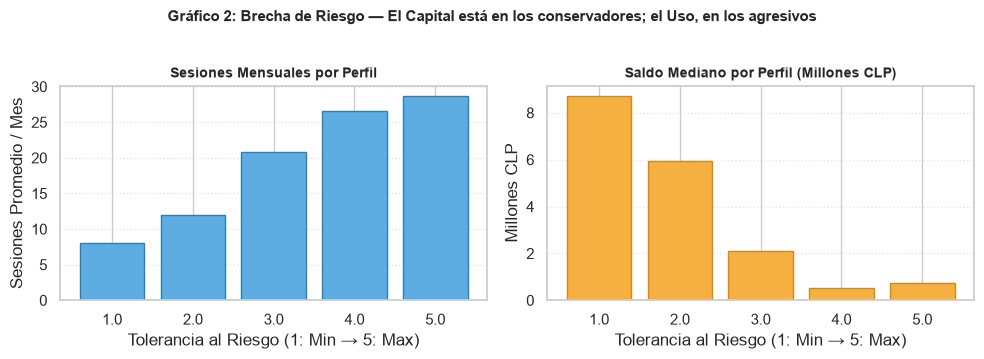

In [23]:
# GRAFICO 2: Matplotlib puro - Engagement y Saldo por Nivel de Riesgo
riesgo = usuarios_copia.groupby('risk_tolerance').agg(
    sesiones_prom=('app_sessions_month', 'mean'),
    saldo_mediano=('total_invested', lambda x: x.median() / 1_000_000)
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

# Subplot 1: Sesiones mensuales
ax1.bar(riesgo['risk_tolerance'].astype(str), riesgo['sesiones_prom'], color='#5dade2', edgecolor='#2980b9')
ax1.set_title("Sesiones Mensuales por Perfil", fontsize=10, fontweight='bold')
ax1.set_xlabel("Tolerancia al Riesgo (1: Min → 5: Max)")
ax1.set_ylabel("Sesiones Promedio / Mes")
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# Subplot 2: Saldo mediano
ax2.bar(riesgo['risk_tolerance'].astype(str), riesgo['saldo_mediano'], color='#f5b041', edgecolor='#d68910')
ax2.set_title("Saldo Mediano por Perfil (Millones CLP)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Tolerancia al Riesgo (1: Min → 5: Max)")
ax2.set_ylabel("Millones CLP")
ax2.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Gráfico 2: Brecha de Riesgo — El Capital está en los conservadores; el Uso, en los agresivos", 
             fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

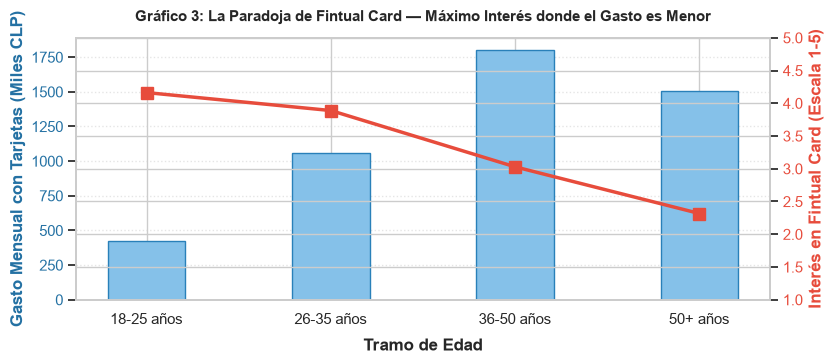

In [24]:
# GRAFICO 3: Matplotlib puro - Paradoja de Fintual Card
df_completo = usuarios_copia.merge(caracteristicas, on='user_id', how='left')

df_completo['tramo_edad'] = pd.cut(
    df_completo['age'], 
    bins=[17, 25, 35, 50, 100], 
    labels=['18-25 años', '26-35 años', '36-50 años', '50+ años']
)

paradoja = df_completo.groupby('tramo_edad', observed=False).agg(
    gasto_k=('gasto_mensual_tarjetas_clp', lambda x: x.mean() / 1_000),
    interes_prom=('interes_fintual_card', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# 1. Barras: Gasto mensual con tarjetas
color_gasto = '#85c1e9'
ax1.bar(paradoja['tramo_edad'], paradoja['gasto_k'], color=color_gasto, edgecolor='#2980b9', width=0.42)
ax1.set_xlabel("Tramo de Edad", fontweight='bold', labelpad=8)
ax1.set_ylabel("Gasto Mensual con Tarjetas (Miles CLP)", color='#2471a3', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2471a3')
ax1.grid(axis='y', linestyle=':', alpha=0.5)

# 2. Linea: Interes declarado
ax2 = ax1.twinx()
color_interes = '#e74c3c'
ax2.plot(paradoja['tramo_edad'], paradoja['interes_prom'], color=color_interes, marker='s', linewidth=2.5, markersize=8)
ax2.set_ylabel("Interés en Fintual Card (Escala 1-5)", color=color_interes, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_interes)
ax2.set_ylim(1, 5)

plt.title("Gráfico 3: La Paradoja de Fintual Card — Máximo Interés donde el Gasto es Menor", 
          fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

In [25]:
vars_clustering = ['age', 'total_invested', 'risk_tolerance', 'months_active', 'app_sessions_month']
# Matriz 1: Escala original estandarizada
scaler_orig = StandardScaler()
X_scaled_orig = scaler_orig.fit_transform(usuarios_copia[vars_clustering])
# Matriz 2: Con transformacion logaritmica en total_invested (para comparar en 2.3)
usuarios_log = usuarios_copia[vars_clustering].copy()
usuarios_log['total_invested'] = np.log1p(usuarios_log['total_invested'])
scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(usuarios_log)
print("Matrices estandarizadas listas:")
print("1. X_scaled_orig (escala bruta):", X_scaled_orig.shape)
print("2. X_scaled_log  (con log1p):    ", X_scaled_log.shape)

Matrices estandarizadas listas:
1. X_scaled_orig (escala bruta): (12000, 5)
2. X_scaled_log  (con log1p):     (12000, 5)


# Clustering Jerarquico

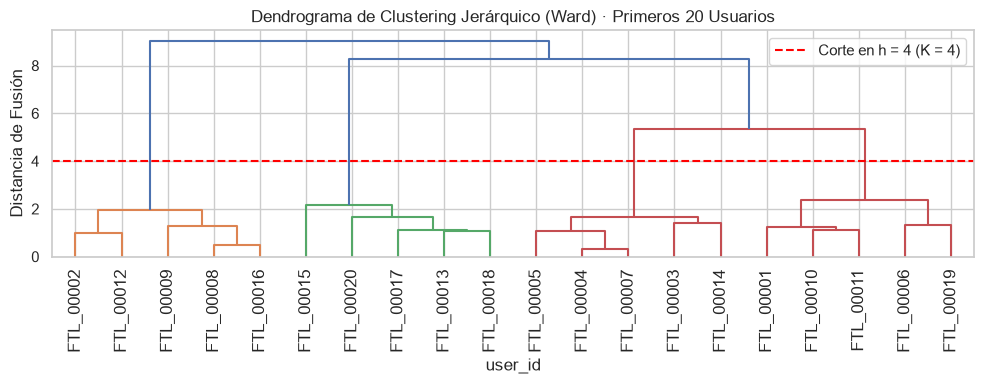

Últimas distancias de fusión: [1.96 2.15 2.36 5.36 8.27 9.02]


In [30]:
# Construccion del dendograma

# 1. Tomamos los primeros 20 usuarios estandarizados
X_20 = X_scaled_log[:20]
user_ids_20 = usuarios_copia['user_id'].iloc[:20].tolist()

# 2. Matriz de enlace Ward y dendrograma
L = linkage(X_20, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(L, labels=user_ids_20, leaf_rotation=90)
plt.axhline(y=4, color="red", linestyle="--", label="Corte en h = 4 (K = 4)")

plt.title("Dendrograma de Clustering Jerárquico (Ward) · Primeros 20 Usuarios")
plt.ylabel("Distancia de Fusión")
plt.xlabel("user_id")
plt.legend()
plt.tight_layout()
plt.show()

print("Últimas distancias de fusión:", L[-6:, 2].round(2))

# Escribir respuesta

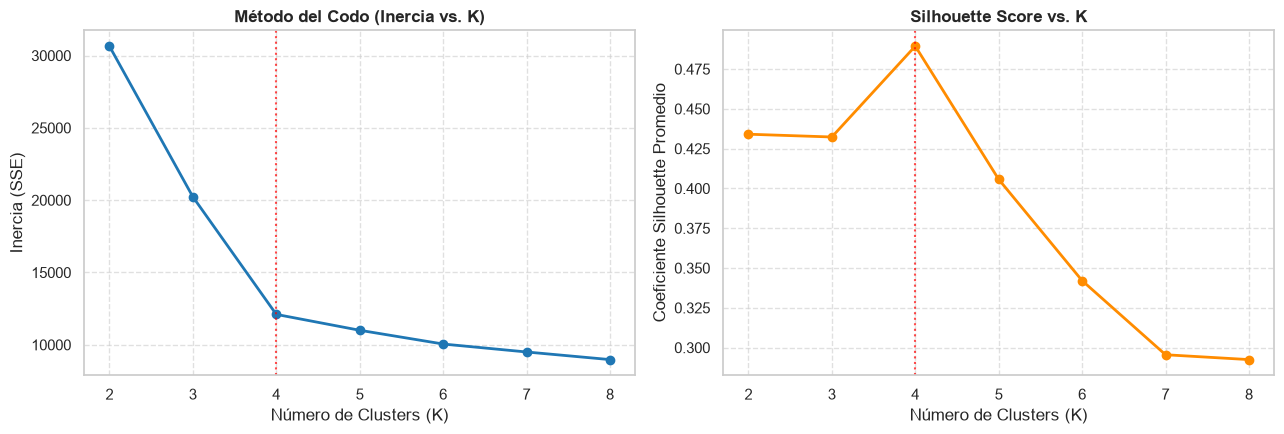

In [40]:
# Metodo K-means

resultados_k = []

for k in range(2,9):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled_log) # Inercia y Silhouette score 
    silhouette = silhouette_score(X_scaled_log, km. labels_)
    resultados_k.append((k, km.inertia_, silhouette))

# Ver dataframe resumen
resumen_kmeans = pd.DataFrame(resultados_k, columns=["K","inercia", "silhouette"])
resumen_kmeans

# Graficos configuracion
fig, ax = plt.subplots(1,2, figsize =(13, 4.5))

# Gráfico del Codo
ax[0].plot(resumen_kmeans.K, resumen_kmeans.inercia, "o-", color="tab:blue", linewidth=2)
ax[0].set_title("Método del Codo (Inercia vs. K)", fontsize=12, weight='bold')
ax[0].set_xlabel("Número de Clusters (K)")
ax[0].set_ylabel("Inercia (SSE)")
ax[0].grid(True, linestyle="--", alpha=0.6)
# Gráfico de Silhouette
ax[1].plot(resumen_kmeans.K, resumen_kmeans.silhouette, "o-", color="darkorange", linewidth=2)
ax[1].set_title("Silhouette Score vs. K", fontsize=12, weight='bold')
ax[1].set_xlabel("Número de Clusters (K)")
ax[1].set_ylabel("Coeficiente Silhouette Promedio")
ax[1].grid(True, linestyle="--", alpha=0.6)

# Resaltar K=4 en ambos gráficos
ax[0].axvline(4, color="red", linestyle=":", alpha=0.7)
ax[1].axvline(4, color="red", linestyle=":", alpha=0.7)

plt.tight_layout()
plt.show()


In [42]:
# 4. Tabla de resultados numéricos
print("Resultados de Evaluación de Clusters:")
display(resumen_kmeans.round(3))

Resultados de Evaluación de Clusters:


,K,inercia,silhouette
0,2,"30,651.02",0.43
1,3,"20,233.89",0.43
2,4,"12,102.81",0.49
3,5,"11,005.14",0.41
4,6,"10,054.24",0.34
5,7,"9,504.09",0.30
6,8,"8,977.18",0.29


# Insertasr respuesta aqui

In [45]:
# 2. Funcion para correr K-Means
def correr_kmeans(k, Zm=X_scaled_log):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(Zm)
    return km, km.labels_
km3, usuarios_copia["k3"] = correr_kmeans(3)
km4, usuarios_copia["k4"] = correr_kmeans(4)
# 3. Funcion para reportar centroides en escala original
def centroides_originales(km):
    c = pd.DataFrame(scaler_log.inverse_transform(km.cluster_centers_), columns=vars_clustering)
    # Recuperamos la escala en pesos chilenos para total_invested
    c['total_invested'] = np.expm1(c['total_invested'])
    c["n"] = np.bincount(km.labels_)
    return c.round(1)
# 3. Funcion para reportar centroides en escala original
def centroides_originales(km):
    c = pd.DataFrame(scaler_log.inverse_transform(km.cluster_centers_), columns=vars_clustering)
    # Recuperamos la escala en pesos chilenos para total_invested
    c['total_invested'] = np.expm1(c['total_invested'])
    c["n"] = np.bincount(km.labels_)
    return c.round(1)
# 4. Reporte y visualizacion
print(f"K=3 · Inercia={km3.inertia_:,.0f} · Silhouette={silhouette_score(X_scaled_log, usuarios_copia.k3):.3f}")
display(centroides_originales(km3))
print(f"K=4 · Inercia={km4.inertia_:,.0f} · Silhouette={silhouette_score(X_scaled_log, usuarios_copia.k4):.3f}")
display(centroides_originales(km4))

K=3 · Inercia=20,234 · Silhouette=0.432


,age,total_invested,risk_tolerance,months_active,app_sessions_month,n
0,35.10,"6,000,320.80",3.50,41.10,21.00,5357
1,23.10,"184,819.60",3.90,9.20,29.50,4049
2,47.40,"8,644,416.90",1.70,51.40,7.60,2594


K=4 · Inercia=12,103 · Silhouette=0.489


,age,total_invested,risk_tolerance,months_active,app_sessions_month,n
0,39.20,"28,125,875.00",4.40,64.00,28.60,1761
1,23.10,"183,439.00",3.90,9.10,29.50,4027
2,47.90,"8,977,646.80",1.70,52.30,7.40,2483
3,33.10,"2,816,240.70",3.00,29.90,17.10,3729


In [ ]:
# Escala original

# Entrenamos K=3 y K=4 con los hiperparámetros exigidos
km3 = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_scaled_log)
km4 = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(X_scaled_log)

df_analisis = usuarios_copia[['age', 'total_invested', 'risk_tolerance', 'months_active', 'app_sessions_month']].copy()
df_analisis['cluster_k3'] = km3.labels_
df_analisis['cluster_k4'] = km4.labels_

# Centroides K=3 en escala original
print("--- Centroides K=3 en Escala Original ---")
display(df_analisis.groupby('cluster_k3').agg({
    'age': 'mean',
    'total_invested': ['mean', 'median'],
    'risk_tolerance': 'mean',
    'months_active': 'mean',
    'app_sessions_month': 'mean',
    'cluster_k3': 'count'
}).round(1))

# Centroides K=4 en escala original
print("\n--- Centroides K=4 en Escala Original ---")
display(df_analisis.groupby('cluster_k4').agg({
    'age': 'mean',
    'total_invested': ['mean', 'median'],
    'risk_tolerance': 'mean',
    'months_active': 'mean',
    'app_sessions_month': 'mean',
    'cluster_k4': 'count'
}).round(1))

--- Centroides K=3 en Escala Original ---


age total_invested              risk_tolerance months_active  \
            mean           mean       median           mean          mean   
cluster_k3                                                                  
0          35.10  12,904,909.80 4,203,700.00           3.50         41.10   
1          23.10     249,368.70   181,300.00           3.90          9.20   
2          47.40  10,486,186.20 8,882,150.00           1.70         51.40   

           app_sessions_month cluster_k3  
                         mean      count  
cluster_k3                                
0                       21.00       5357  
1                       29.50       4049  
2                        7.60       2594


--- Centroides K=4 en Escala Original ---


age total_invested               risk_tolerance months_active  \
            mean           mean        median           mean          mean   
cluster_k4                                                                   
0          39.20  32,176,411.90 27,699,000.00           4.40         64.00   
1          23.10     246,126.70    180,700.00           3.90          9.10   
2          47.90  10,729,297.80  9,112,700.00           1.70         52.30   
3          33.10   3,499,008.60  2,774,100.00           3.00         29.90   

           app_sessions_month cluster_k4  
                         mean      count  
cluster_k4                                
0                       28.60       1761  
1                       29.50       4027  
2                        7.40       2483  
3                       17.10       3729

In [56]:
# Perfilamiento accionable

# 1. Aseguramos el cluster K=4 en usuarios_copia y unimos con user_demographics
usuarios_copia['cluster'] = km4.labels_
df_completo = usuarios_copia.merge(caracteristicas, on='user_id', how='left')

# 2. Construcción de la Tabla Maestra de Segmentos
resumen_segmentos = df_completo.groupby('cluster').agg(
    n_usuarios=('user_id', 'count'),
    edad_prom=('age', 'mean'),
    antiguedad_meses=('months_active', 'mean'),
    sesiones_mes=('app_sessions_month', 'mean'),
    riesgo_prom=('risk_tolerance', 'mean'),
    saldo_prom_clp=('total_invested', 'mean'),
    saldo_mediana_clp=('total_invested', 'median'),
    aum_total_m_clp=('total_invested', lambda x: x.sum() / 1_000_000), # Millones de pesos
    gasto_tarjetas_prom=('gasto_mensual_tarjetas_clp', 'mean'),
    pct_con_tarjeta_credito=('tiene_tarjeta_credito', lambda x: (x == 'Sí').mean() * 100),
    banco_principal=('banco_principal', lambda x: x.mode()[0]),
    billetera_top=('billetera_digital_principal', lambda x: x.mode()[0]),
    region_top=('region', lambda x: x.mode()[0] if not x.mode().empty else 'N/A'),
    interes_fintual_card=('interes_fintual_card', 'mean'),
    tasa_respuesta_interes=('interes_fintual_card', lambda x: x.notnull().mean() * 100)
).reset_index()

# Añadimos el % de clientes y el % de AUM sobre el total de Fintual
resumen_segmentos['pct_usuarios'] = (resumen_segmentos['n_usuarios'] / len(df_completo)) * 100
total_aum_fintual = df_completo['total_invested'].sum() / 1_000_000
resumen_segmentos['pct_aum_fintual'] = (resumen_segmentos['aum_total_m_clp'] / total_aum_fintual) * 100

# 3. Asignación de Nombres de Marketing
nombres_marketing = {
    0: 'Inversionistas Wealth',
    1: 'Jóvenes Transaccionales',
    2: 'Conservadores Tradicionales',
    3: 'Millennials en Crecimiento'
}
resumen_segmentos['nombre_segmento'] = resumen_segmentos['cluster'].map(nombres_marketing)

# Mostramos la tabla resumen
cols_mostrar = [
    'cluster', 'nombre_segmento', 'n_usuarios', 'pct_usuarios', 'pct_aum_fintual',
    'edad_prom', 'saldo_mediana_clp', 'gasto_tarjetas_prom', 'pct_con_tarjeta_credito',
    'banco_principal', 'billetera_top', 'interes_fintual_card', 'region_top'
]

display(resumen_segmentos[cols_mostrar].round(2))

,cluster,nombre_segmento,n_usuarios,pct_usuarios,pct_aum_fintual,edad_prom,saldo_mediana_clp,gasto_tarjetas_prom,pct_con_tarjeta_credito,banco_principal,billetera_top,interes_fintual_card,region_top
0,0,Inversionistas Wealth,1761,14.68,58.21,39.23,"27,699,000.00","2,664,222.60",96.88,Banco de Chile,Ninguna,3.27,Metropolitana de Santiago
1,1,Jóvenes Transaccionales,4027,33.56,1.02,23.10,"180,700.00","408,439.28",23.44,BancoEstado,Mercado Pago,4.18,Metropolitana de Santiago
2,2,Conservadores Tradicionales,2483,20.69,27.37,47.88,"9,112,700.00","1,497,828.43",93.19,Banco de Chile,Ninguna,2.35,Metropolitana de Santiago
3,3,Millennials en Crecimiento,3729,31.08,13.40,33.09,"2,774,100.00","1,022,293.91",81.12,Banco de Chile,Ninguna,3.90,Metropolitana de Santiago


### Los 4 buyers
* Inversionistas Wealth: Son personas que en promedio tiene 39 años, con un una inversion tipica de 28 millones aprox , gasto promedio de las tarjetas es de 2,7 millones aprox y un 96,88% tiene tarjetas de credito. Su banco principal es el 'Banco de Chile'
* Jovenes transaccionales: Son las personas mas jovenes promediando 23 años de edad aprxoimadamente, aportan un inversion tipica de 180 mil. Su gasto promedio en tarjeta es de 408 mil aprox, solo el 23,44% tiene tarjeta de credito y el banco princiapl es 'BancoEstado'
* Conservadores (La resistencia): Promedian 48 años aprox, tiene un inversion tipica de de 9,12 millones de pesos. Su gasto promedio en tarjeta asciende aproximadamente a los 1,5 millones de pesos y el 93,19% poseen un tarjeta de credito. Su banco principal es el 'Banco de Chile'
* Millennials es ascenso: Son las personas que promedian 33 años de edad, con una imbersion tipica de 2,8 millones de pesos, gastando 1 millon de pesos con tarjetas aprox y el 81% posee tarjeta de credito. EL banco principal es el 'Banco De Chile'

### Cluster interesado
El segmento que presenta un mayor interes para fintual son los Millenials en crecimiento. Principalmente porque es el 2do grupo mas alto en interes para adoptar la tarjeta solo por detas de los Jovenes transaccionales (0.28 de diferencia). Pero estos presentan un gasto promedio en tarjeta superior a los jovenes, por lo que es más atractivo trabajar con ellos y presentan un saldo de inversion superior 


